In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

plt.style.use('default')

In [ ]:
df = pd.read_csv(r'Season_23_dataset_1.csv')

df.drop(columns = ['Unnamed: 0'], inplace = True)

df

,Position,Country,City/Town,Year,PM2.5,Temporal coverage,PM10,Temporal coverage.1,Database version (year)
0,1,India,Kanpur,2016,173,>75%,319,NaN,2018
1,2,India,Faridabad,2016,172,>75%,316,NaN,2018
2,3,India,Gaya,2016,149,50% -< 75%,275,NaN,2018
3,4,India,Varanasi,2016,146,>75%,260,NaN,2018
4,5,India,Patna,2016,144,>75%,266,NaN,2018
...,...,...,...,...,...,...,...,...,...
495,496,Poland,Lublin,2016,27,>75%,31,>75%,2018
496,497,Poland,Siedlce,2016,27,>75%,29,>75%,2018
497,498,Poland,Trzebinia,2016,27,>75%,35,>75%,2018
498,499,El Salvador,San Salvador,2016,27,50% -< 75%,59,NaN,2018


## `Problem 1 to 5`:

Dataset link: https://tinyurl.com/2fe6vz4u

**Add a label to every axis and add a proper title for the charts. Also add proper labels if there are multiple representations.** Then, you can customize it as your wish.

### **`Problem-1:`** Draw a line plot of which, the x-axis is the "Year" and the y-axis is sum of "PM2.5" of two countries Iran and China.

In [13]:
iran = df[df['Country'].str.contains('Iran')]
iran

,Position,Country,City/Town,Year,PM2.5,Temporal coverage,PM10,Temporal coverage.1,Database version (year)
83,84,Iran,Hamedan,2013,66,NaN,149,NaN,2018
104,105,Iran,Qods,2016,61,NaN,140,NaN,2018
126,127,Iran,Ahvaz,2016,58,NaN,132,NaN,2018
144,145,Iran,Genaveh,2016,56,NaN,129,NaN,2018
153,154,Iran,Asaluyeh,2016,55,NaN,126,NaN,2018
189,190,Iran,Zabol,2016,50,NaN,115,NaN,2018
239,240,Iran,Baghershahr,2016,46,NaN,105,NaN,2018
240,241,Iran,Bushehr,2016,46,NaN,105,NaN,2018
264,265,Iran,Dehloran,2016,44,NaN,100,NaN,2018
265,266,Iran,Mehran,2016,44,NaN,102,NaN,2018


In [15]:
df.query("Country == 'Iran'")

,Position,Country,City/Town,Year,PM2.5,Temporal coverage,PM10,Temporal coverage.1,Database version (year)
83,84,Iran,Hamedan,2013,66,NaN,149,NaN,2018
104,105,Iran,Qods,2016,61,NaN,140,NaN,2018
126,127,Iran,Ahvaz,2016,58,NaN,132,NaN,2018
144,145,Iran,Genaveh,2016,56,NaN,129,NaN,2018
153,154,Iran,Asaluyeh,2016,55,NaN,126,NaN,2018
189,190,Iran,Zabol,2016,50,NaN,115,NaN,2018
239,240,Iran,Baghershahr,2016,46,NaN,105,NaN,2018
240,241,Iran,Bushehr,2016,46,NaN,105,NaN,2018
264,265,Iran,Dehloran,2016,44,NaN,100,NaN,2018
265,266,Iran,Mehran,2016,44,NaN,102,NaN,2018


In [20]:
iran = df.query("Country == 'Iran'").groupby('Year')['PM2.5'].sum()
china = df.query("Country == 'China'").groupby('Year')['PM2.5'].sum()

print(iran.index)
print()

print(iran.values)

Index([2012, 2013, 2014, 2016], dtype='int64', name='Year')

[  37   66   31 1453]


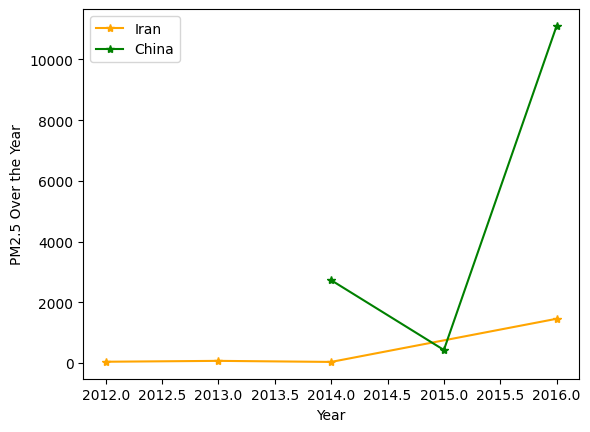

In [26]:
plt.plot(iran.index, iran.values, label = 'Iran', color = 'orange', marker = '*')
plt.plot(china.index, china.values, label = 'China', color = 'green', marker = '*')
plt.xlabel('Year')
plt.ylabel('PM2.5 Over the Year')
plt.legend()

### **`Problem-2:`** Draw a histogram of the  column "PM10" of which the y-axis represents the probability (see the documentation how to draw the probability).

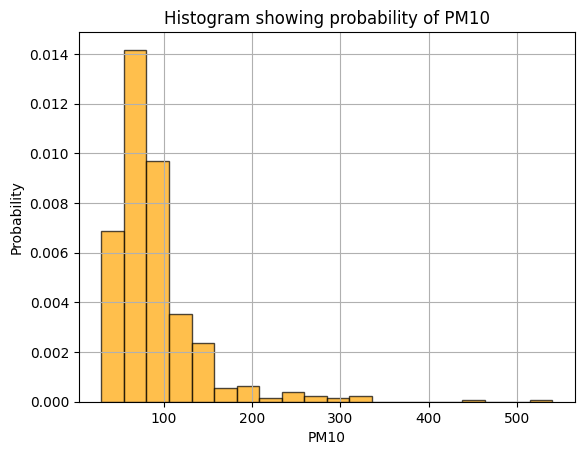

In [38]:
plt.hist(df['PM10'], bins = 20, density = True, color = 'orange', alpha = 0.7, edgecolor = 'black')
plt.xlabel('PM10')
plt.ylabel('Probability')
plt.title("Histogram showing probability of PM10")
plt.grid()

### **`Problem-3:`** Draw a scatter plot where x-axis represents "PM2.5" and y-axis represents "PM10" for two countries Poland and Chile.

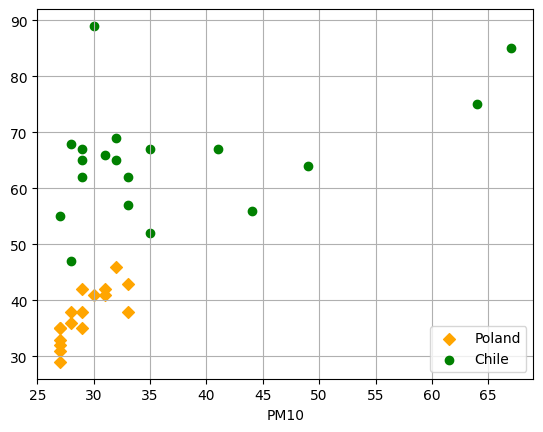

In [47]:
poland = df.query("Country == 'Poland'")
chile = df.query("Country == 'Chile'")

plt.scatter(poland['PM2.5'],poland['PM10'],marker="D",color='orange',label='Poland')
plt.scatter(chile['PM2.5'],chile['PM10'],marker="o",color='green',label='Chile')

plt.xlabel('PM2.5')
plt.xlabel('PM10')
plt.grid()

plt.legend()



### **`Problem-4:`** Draw a pie chart of top 5 most frequent countries.

([<matplotlib.patches.Wedge at 0x1e92d864350>,
 [Text(-0.6965605902346648, 0.8513538301622514, 'China'),
  Text(0.157335564878122, -1.0886898180953484, 'Iran'),
  Text(0.7429696146360116, -0.8111696195788008, 'India'),
  Text(1.003228249501556, -0.45114640572883186, 'Chile'),
  Text(1.0899097351340639, -0.1486498209215032, 'Poland')],
 [Text(-0.37994214012799893, 0.4643748164521371, '71.83%'),
  Text(0.08581939902443018, -0.5938308098701899, '10.91%'),
  Text(0.40525615343782445, -0.44245615613389133, '8.12%'),
  Text(0.5472154088190305, -0.2460798576702719, '4.82%'),
  Text(0.5944962191640347, -0.08108172050263811, '4.31%')])

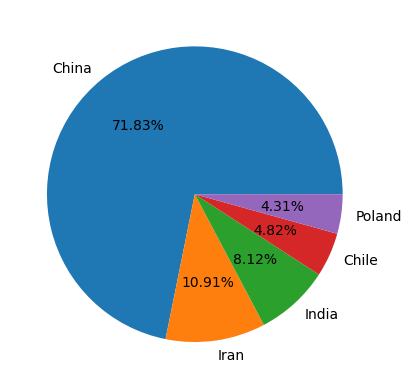

In [59]:
top_5 = df['Country'].value_counts().head()

plt.pie(top_5, labels = top_5.index, autopct= "%.2f%%")

### **`Problem-5:`** Draw a bar chart which represents the counts of top 5 most frequent countries.



<BarContainer object of 5 artists>

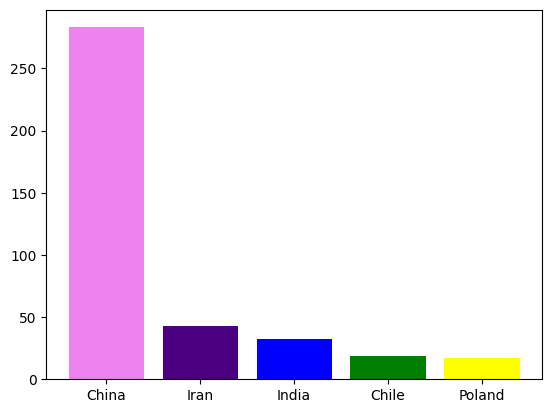

In [66]:
plt.bar(top_5.index, top_5.values, color = ['violet', 'indigo', 'blue', 'green', 'yellow'])

##`Problem 6-10`
Data Set - https://docs.google.com/spreadsheets/d/e/2PACX-1vTJh6X4_mqixWsfK9mgkllGQkKYW9Wj9kOIMGY2uYsWeS8n5np87DO-SDGQWJ1HXEnxiOVFVzYFYEcR/pub?gid=558678488&single=true&output=csv

This is a Sales data of any company in a Year.


###`Problem-6`
Show a line plot of Total Profit for each month with below styling.
* Dotted Line
* Line Color Blue
* Show Legend at top left
* Circle Marker

In [67]:
df2 = pd.read_csv(r"Session_23_dataset_2.csv")
df2

,month_number,facecream,facewash,toothpaste,bathingsoap,shampoo,moisturizer,total_units,total_profit
0,1,2500,1500,5200,9200,1200,1500,21100,211000
1,2,2630,1200,5100,6100,2100,1200,18330,183300
2,3,2140,1340,4550,9550,3550,1340,22470,224700
3,4,3400,1130,5870,8870,1870,1130,22270,222700
4,5,3600,1740,4560,7760,1560,1740,20960,209600
5,6,2760,1555,4890,7490,1890,1555,20140,201400
6,7,2980,1120,4780,8980,1780,1120,29550,295500
7,8,3700,1400,5860,9960,2860,1400,36140,361400
8,9,3540,1780,6100,8100,2100,1780,23400,234000
9,10,1990,1890,8300,10300,2300,1890,26670,266700


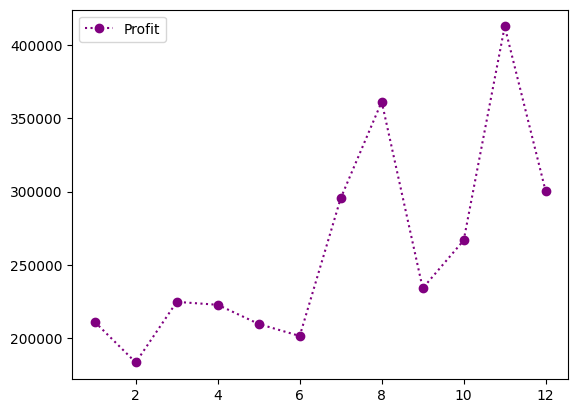

In [76]:
plt.plot(df2['month_number'], df2['total_profit'], linestyle = 'dotted', color = 'purple', marker = 'o', label = 'Profit')
plt.legend(loc = "upper left")